In [11]:
import cv2
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path

    1. Defining Configuration
    2. Loading dataset
    3. Data preprocessing
        3.1 Normalize dataset
    4. Defining classes
    5. Building model
    6. Training model
    7. Comparing faces

**1. Defining configuration**

In [12]:
CONFIGURATION = {
    "IMAGE_SIZE": 112,
    "PATCH_SIZE": 8,
    "HIDDEN_SIZE": 128,
    "NUM_HEADS": 4,
    "MLP_SIZE": 256,
    "SEED": 42,
    "NUM_TRANSFORMER_BLOCKS": 4,
    "EMBEDDING_SIZE": 128,
    "BATCH_SIZE": 32,
    "EPOCHS": 1,
    "AUTOTUNE": tf.data.AUTOTUNE
}

**2. Loading dataset**

In [13]:
df_train = pd.read_csv('./dataset/Dataset.csv', dtype = 'str')

In [14]:
df_train = df_train.dropna(subset=["id", "label"])
print("Dataset shape:", df_train.shape)
print(df_train.head())

Dataset shape: (2562, 2)
                        id             label
0  Robert Downey Jr_87.jpg  Robert Downey Jr
1       Lisa Kudrow_64.jpg       Lisa Kudrow
2   Ellen Degeneres_34.jpg   Ellen Degeneres
3      Billie Eilish_3.jpg     Billie Eilish
4    Hrithik Roshan_35.jpg    Hrithik Roshan


In [15]:
ROOT = Path.cwd()
DATASET = ROOT / "dataset" / "Original Images"
DATASET_FACES = ROOT / "dataset" / "Faces"

def load_images(folder):
    images = []

    for path in folder.rglob("*"):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image = cv2.imread(str(path))

            if image is not None:
                images.append({
                    "path": path,
                    "image": image
                })

    return images

faces = load_images(DATASET_FACES)

print(f"Loaded {len(faces)} images")

Loaded 2562 images


In [16]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET,
    validation_split=0.2,
    subset="training",
    seed= CONFIGURATION["SEED"],
    image_size=(CONFIGURATION["IMAGE_SIZE"], CONFIGURATION["IMAGE_SIZE"]),
    batch_size= CONFIGURATION["BATCH_SIZE"],
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET,
    validation_split=0.2,
    subset="validation",
    seed= CONFIGURATION["SEED"],
    image_size=(CONFIGURATION["IMAGE_SIZE"], CONFIGURATION["IMAGE_SIZE"]),
    batch_size= CONFIGURATION["BATCH_SIZE"],
    label_mode="int"
)

class_names = train_ds.class_names
num_identities = len(class_names)

print("Number of identities:", num_identities)
print("Identities:", class_names)

Found 2562 files belonging to 31 classes.
Using 2050 files for training.
Found 2562 files belonging to 31 classes.
Using 512 files for validation.
Number of identities: 31
Identities: ['Akshay Kumar', 'Alexandra Daddario', 'Alia Bhatt', 'Amitabh Bachchan', 'Andy Samberg', 'Anushka Sharma', 'Billie Eilish', 'Brad Pitt', 'Camila Cabello', 'Charlize Theron', 'Claire Holt', 'Courtney Cox', 'Dwayne Johnson', 'Elizabeth Olsen', 'Ellen Degeneres', 'Henry Cavill', 'Hrithik Roshan', 'Hugh Jackman', 'Jessica Alba', 'Kashyap', 'Lisa Kudrow', 'Margot Robbie', 'Marmik', 'Natalie Portman', 'Priyanka Chopra', 'Robert Downey Jr', 'Roger Federer', 'Tom Cruise', 'Vijay Deverakonda', 'Virat Kohli', 'Zac Efron']


**3. Data Preprocessing**

3.1 Normalize dataset

In [17]:
# Convert pixel values from [0, 255] to [0, 1].
def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = (
    train_ds
    .map(normalize_images, num_parallel_calls=CONFIGURATION["AUTOTUNE"])
    .prefetch(CONFIGURATION["AUTOTUNE"])
)

val_ds = (
    val_ds
    .map(normalize_images, num_parallel_calls=CONFIGURATION["AUTOTUNE"])
    .prefetch(CONFIGURATION["AUTOTUNE"])
)

In [ ]:
images, labels = next(iter(train_ds))

image = images[0]
label = labels[0]

In [21]:
image

<tf.Tensor: shape=(112, 112, 3), dtype=float32, numpy=
array([[[0.6471463 , 0.60400903, 0.9726365 ],
        [0.6505602 , 0.60742295, 0.9760504 ],
        [0.65498376, 0.6118465 , 0.98047394],
        ...,
        [0.7989846 , 0.75584733, 0.9760854 ],
        [0.7831337 , 0.7282317 , 0.96804273],
        [0.77081823, 0.70807314, 0.98951584]],

       [[0.6494853 , 0.60634804, 0.97497547],
        [0.64806706, 0.6049298 , 0.97355723],
        [0.6554098 , 0.61227256, 0.9809    ],
        ...,
        [0.7827906 , 0.73965335, 0.9598914 ],
        [0.78265774, 0.7277558 , 0.9675667 ],
        [0.7697621 , 0.707017  , 0.9884597 ]],

       [[0.6485644 , 0.60542715, 0.97405463],
        [0.64254206, 0.5994048 , 0.96803224],
        [0.65521705, 0.6120798 , 0.9807073 ],
        ...,
        [0.7845177 , 0.74138045, 0.96161854],
        [0.78098744, 0.7260855 , 0.9658964 ],
        [0.7668069 , 0.7040618 , 0.9855045 ]],

       ...,

       [[0.37922087, 0.30506548, 0.27980444],
        [0.52

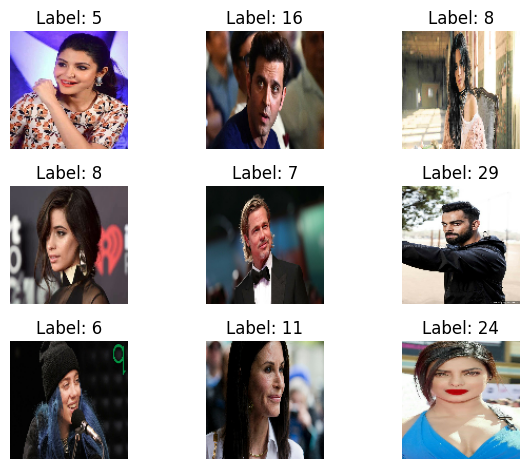

In [ ]:
for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i].numpy())
    plt.title(f"Label: {labels[i].numpy()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

**4. Defining classes**

In [ ]:
class PatchEncoder(tf.keras.layers.Layer):

    def __init__(self, image_size, patch_size, hidden_size):
        super().__init__()

        self.patch_size = patch_size
        self.hidden_size = hidden_size

        self.num_patches = (image_size // patch_size) ** 2

        self.patch_dim = patch_size * patch_size * 3

        self.projection = tf.keras.layers.Dense(hidden_size)

        self.position_embedding = tf.keras.layers.Embedding(
            input_dim=self.num_patches,
            output_dim=hidden_size
        )

    def call(self, images):

        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )

        batch_size = tf.shape(images)[0]

        patches = tf.reshape(
            patches,
            [batch_size, self.num_patches, self.patch_dim]
        )

        patches = tf.ensure_shape(
            patches,
            [None, self.num_patches, self.patch_dim]
        )

        positions = tf.range(self.num_patches)

        encoded = self.projection(patches)

        encoded += self.position_embedding(positions)

        return encoded

In [ ]:
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, hidden_size, num_heads, mlp_size, dropout=0.1):
        super().__init__()

        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=hidden_size // num_heads,
            dropout=dropout
        )

        self.dropout1 = tf.keras.layers.Dropout(dropout)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.mlp = tf.keras.Sequential([
            tf.keras.layers.Dense(mlp_size, activation="gelu"),
            tf.keras.layers.Dropout(dropout),
            tf.keras.layers.Dense(hidden_size),
            tf.keras.layers.Dropout(dropout)
        ])

    def call(self, x, training=None):
        normalized = self.norm1(x)

        attention_output = self.attention(
            normalized,
            normalized,
            training=training
        )

        x = x + self.dropout1(
            attention_output,
            training=training
        )

        x = x + self.mlp(
            self.norm2(x),
            training=training
        )

        return x


**5. Building model**

In [ ]:

def build_vit_face_model(num_identities):
    inputs = tf.keras.layers.Input(
        shape=(CONFIGURATION["IMAGE_SIZE"], CONFIGURATION["IMAGE_SIZE"], 3),
        name="face_image"
    )

    x = PatchEncoder(
        CONFIGURATION["IMAGE_SIZE"],
        CONFIGURATION["PATCH_SIZE"],
        CONFIGURATION["HIDDEN_SIZE"]
    )(inputs)

    for _ in range(CONFIGURATION["NUM_TRANSFORMER_BLOCKS"]):
        x = TransformerBlock(
            CONFIGURATION["HIDDEN_SIZE"],
            CONFIGURATION["NUM_HEADS"],
            CONFIGURATION["MLP_SIZE"]
        )(x)

    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(256, activation="gelu")(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    embedding = tf.keras.layers.Dense(
        CONFIGURATION["EMBEDDING_SIZE"],
        name="raw_embedding"
    )(x)

    embedding = tf.keras.layers.UnitNormalization(
        axis=-1,
        name="embedding"
    )(embedding)

    identity = tf.keras.layers.Dense(
        num_identities,
        activation="softmax",
        name="identity"
    )(embedding)

    training_model = tf.keras.Model(
        inputs=inputs,
        outputs=identity,
        name="vit_face_classifier"
    )

    embedding_model = tf.keras.Model(
        inputs=inputs,
        outputs=embedding,
        name="vit_face_embedding"
    )

    return training_model, embedding_model


**6. Training model**

In [ ]:
training_model, embedding_model = build_vit_face_model(
    num_identities=num_identities
)

training_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )
]

history = training_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CONFIGURATION["EPOCHS"],
    callbacks=callbacks
)

# embedding_model.save("vit_face_embedding.keras")


65/65 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.0446 - loss: 3.4206 - val_accuracy: 0.0391 - val_loss: 3.4199


**7. Comparing faces**

In [ ]:
def load_face(path):
    image = tf.keras.utils.load_img(
        path,
        target_size=(CONFIGURATION["IMAGE_SIZE"], CONFIGURATION["IMAGE_SIZE"]),
        color_mode="rgb"
    )
    
    image = tf.keras.utils.img_to_array(image)
    image = image / 255.0

    return tf.expand_dims(image, axis=0)


def get_face_embedding(image_path):
    image = load_face(image_path)

    embedding = embedding_model(
        image,
        training=False
    )

    return embedding.numpy()[0]


def cosine_similarity(embedding1, embedding2):
    embedding1 = embedding1 / (
        np.linalg.norm(embedding1) + 1e-10
    )
    embedding2 = embedding2 / (
        np.linalg.norm(embedding2) + 1e-10
    )

    return float(np.dot(embedding1, embedding2))


face1 = get_face_embedding(DATASET_FACES/"Akshay Kumar_0.jpg")
face2 = get_face_embedding(DATASET_FACES/"Henry Cavill_5.jpg")

similarity = cosine_similarity(face1, face2)

print("Cosine similarity:", similarity)


Cosine similarity: 0.9994916319847107


In [ ]:
threshold = 0.70  # Example only; NOT a validated threshold.

if similarity >= threshold:
    print("Similar embeddings")
else:
    print("Dissimilar embeddings")

Similar embeddings
